In [8]:
import pandas as pd
import numpy as np

# Set random seed for reproducibility
np.random.seed(42)
n_samples = 1000

# Generating a dataset for Housing Prices
data = {
    'House_ID': [f'H{i:04d}' for i in range(1, n_samples + 1)],
    'Area_SqFt': np.random.randint(800, 5000, size=n_samples),
    'Bedrooms': np.random.randint(1, 6, size=n_samples),
    'Age_Years': np.random.randint(0, 50, size=n_samples),
    'Distance_to_Center_Km': np.random.uniform(1, 30, size=n_samples),
    'Has_Garden': np.random.choice([0, 1], size=n_samples, p=[0.4, 0.6])
}

df = pd.DataFrame(data)

# Heuristic-based price generation with noise
base_price = 50000
price_sqft = df['Area_SqFt'] * 150
price_bedrooms = df['Bedrooms'] * 25000
price_age = -df['Age_Years'] * 1500
price_distance = -df['Distance_to_Center_Km'] * 3000
price_garden = df['Has_Garden'] * 30000
noise = np.random.normal(0, 20000, n_samples)

df['Price'] = base_price + price_sqft + price_bedrooms + price_age + price_distance + price_garden + noise
df['Price'] = df['Price'].clip(lower=40000).round(-2)

# Classifying houses as "Expensive" (1) or "Affordable" (0) for classification downstream
median_price = df['Price'].median()
df['Price_Category'] = np.where(df['Price'] > median_price, 'Expensive', 'Affordable')

# Display the new dataset
display(df.head())
print(f'Total count: {len(df)} rows')
print(f'Median Price: ${median_price:,.2f}')

,House_ID,Area_SqFt,Bedrooms,Age_Years,Distance_to_Center_Km,Has_Garden,Price,Price_Category
0,H0001,1660,2,3,14.166047,0,286200.0,Affordable
1,H0002,4572,5,33,20.959953,1,780500.0,Expensive
2,H0003,3892,1,47,5.076036,0,550800.0,Expensive
3,H0004,1266,1,17,15.082101,0,229600.0,Affordable
4,H0005,4244,1,39,1.798565,0,594900.0,Expensive


Total count: 1000 rows
Median Price: $513,600.00


In [9]:
# Check for missing values in each column
print("Missing values per column:")
display(df.isnull().sum())

print("\n--- Detailed DataFrame Info ---")
df.info()

Missing values per column:


,0
House_ID,0
Area_SqFt,0
Bedrooms,0
Age_Years,0
Distance_to_Center_Km,0
Has_Garden,0
Price,0
Price_Category,0



--- Detailed DataFrame Info ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   House_ID               1000 non-null   object 
 1   Area_SqFt              1000 non-null   int64  
 2   Bedrooms               1000 non-null   int64  
 3   Age_Years              1000 non-null   int64  
 4   Distance_to_Center_Km  1000 non-null   float64
 5   Has_Garden             1000 non-null   int64  
 6   Price                  1000 non-null   float64
 7   Price_Category         1000 non-null   object 
dtypes: float64(2), int64(4), object(2)
memory usage: 62.6+ KB


In [10]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, accuracy_score

# Define Features (X) and Target (y) using the new housing dataset
# Excluding House_ID, Price (continuous target), and Price_Category (categorical target)
X = df.drop(columns=['House_ID', 'Price', 'Price_Category'])
y = df['Price_Category'].map({'Expensive': 1, 'Affordable': 0})  # Encode target variable

# Split the dataset into 80% training and 20% testing
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# Scale the features for better gradient convergence in Logistic Regression
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Initialize and train the Logistic Regression model
model = LogisticRegression(random_state=42)
model.fit(X_train_scaled, y_train)

# Make predictions
y_pred = model.predict(X_test_scaled)

# Evaluate model performance
accuracy = accuracy_score(y_test, y_pred)
print(f"Accuracy Score: {accuracy:.2%}\n")

print("Classification Report:")
print(classification_report(y_test, y_pred, target_names=['Affordable', 'Expensive']))

Accuracy Score: 98.00%

Classification Report:
              precision    recall  f1-score   support

  Affordable       0.98      0.98      0.98       100
   Expensive       0.98      0.98      0.98       100

    accuracy                           0.98       200
   macro avg       0.98      0.98      0.98       200
weighted avg       0.98      0.98      0.98       200



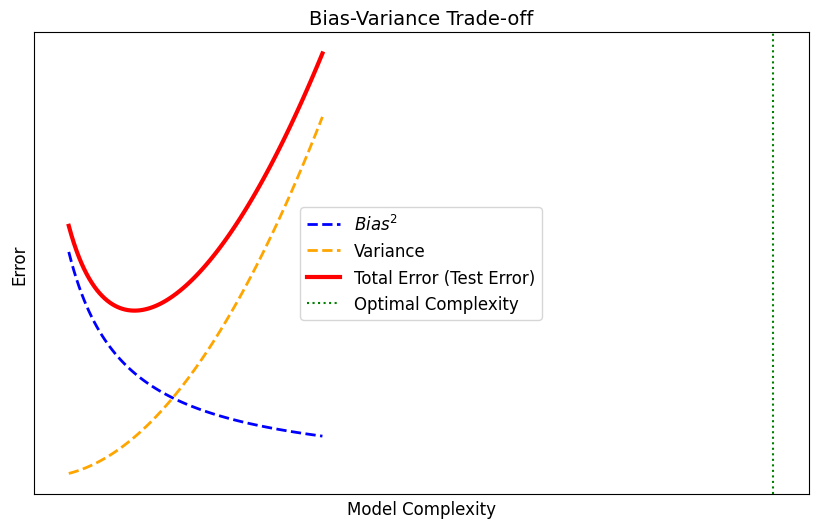

In [2]:
import numpy as np
import matplotlib.pyplot as plt

# Create dummy data representing model complexity vs error
model_complexity = np.linspace(1, 10, 100)
bias_squared = 10 / (model_complexity + 1)
variance = 0.08 * (model_complexity ** 2)
total_error = bias_squared + variance + 0.5 # with some irreducible error

# Plotting Bias-Variance Trade-off
plt.figure(figsize=(10, 6))
plt.plot(model_complexity, bias_squared, label='$Bias^2$', color='blue', linewidth=2, linestyle='--')
plt.plot(model_complexity, variance, label='Variance', color='orange', linewidth=2, linestyle='--')
plt.plot(model_complexity, total_error, label='Total Error (Test Error)', color='red', linewidth=3)

# Formatting
plt.title('Bias-Variance Trade-off', fontsize=14)
plt.xlabel('Model Complexity', fontsize=12)
plt.ylabel('Error', fontsize=12)
plt.axvline(x=np.argmin(total_error), color='green', linestyle=':', label='Optimal Complexity')
plt.xticks([])
plt.yticks([])
plt.legend(fontsize=12)
plt.grid(True, alpha=0.3)
plt.show()

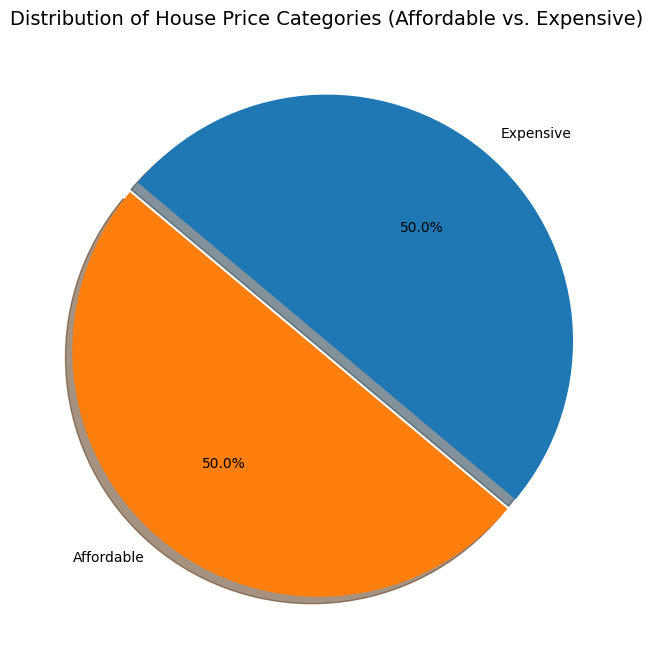

In [11]:
import matplotlib.pyplot as plt

# Count the occurrences of each category
category_counts = df['Price_Category'].value_counts()

# Plot the pie chart
plt.figure(figsize=(8, 8))
plt.pie(
    category_counts,
    labels=category_counts.index,
    autopct='%1.1f%%',
    startangle=140,
    colors=['#ff7f0e', '#1f77b4'],
    explode=(0.05, 0),
    shadow=True
)
plt.title('Distribution of House Price Categories (Affordable vs. Expensive)', fontsize=14)
plt.show()

In [12]:
import ipywidgets as widgets
from IPython.display import display, clear_output
import pandas as pd
import numpy as np

# Create interactive input widgets
area_widget = widgets.IntSlider(value=2000, min=800, max=5000, step=50, description='Area (SqFt):')
bedrooms_widget = widgets.IntSlider(value=3, min=1, max=5, step=1, description='Bedrooms:')
age_widget = widgets.IntSlider(value=10, min=0, max=50, step=1, description='Age (Years):')
distance_widget = widgets.FloatSlider(value=10.0, min=1.0, max=30.0, step=0.5, description='Distance (Km):')
garden_widget = widgets.Dropdown(options=[('No', 0), ('Yes', 1)], value=0, description='Has Garden?')

predict_button = widgets.Button(description="Predict Price Class", button_style='primary')
output_area = widgets.Output()

def make_prediction(b):
    with output_area:
        clear_output()

        # Prepare input features dataframe matching training schema
        input_data = pd.DataFrame([{
            'Area_SqFt': area_widget.value,
            'Bedrooms': bedrooms_widget.value,
            'Age_Years': age_widget.value,
            'Distance_to_Center_Km': distance_widget.value,
            'Has_Garden': garden_widget.value
        }])

        # Scale features with our trained scaler
        input_scaled = scaler.transform(input_data)

        # Predict target class and probabilities
        prediction = model.predict(input_scaled)[0]
        probability = model.predict_proba(input_scaled)[0]

        status = 'Expensive' if prediction == 1 else 'Affordable'

        print(f"### Prediction Result: {status} ###")
        print(f"Probability of Affordable: {probability[0] * 100:.2f}%")
        print(f"Probability of Expensive: {probability[1] * 100:.2f}%")

predict_button.on_click(make_prediction)

# Layout container
ui = widgets.VBox([
    widgets.HTML(value="<h3>Test House Classification Model</h3>"),
    area_widget,
    bedrooms_widget,
    age_widget,
    distance_widget,
    garden_widget,
    widgets.Label(""),
    predict_button,
    output_area
])

display(ui)